DATA SHAPES
X_train: (7742, 768)
y_train: (7742,)
X_val:   (1659, 768)
y_val:   (1659,)
X_test:  (1659, 768)
y_test:  (1659,)

Number of cancer types: 33

Cancer classes:
 0: acute myeloid leukemia
 1: adrenocortical cancer
 2: bladder urothelial carcinoma
 3: brain lower grade glioma
 4: breast invasive carcinoma
 5: cervical & endocervical cancer
 6: cholangiocarcinoma
 7: colon adenocarcinoma
 8: diffuse large B-cell lymphoma
 9: esophageal carcinoma
10: glioblastoma multiforme
11: head & neck squamous cell carcinoma
12: kidney chromophobe
13: kidney clear cell carcinoma
14: kidney papillary cell carcinoma
15: liver hepatocellular carcinoma
16: lung adenocarcinoma
17: lung squamous cell carcinoma
18: mesothelioma
19: ovarian serous cystadenocarcinoma
20: pancreatic adenocarcinoma
21: pheochromocytoma & paraganglioma
22: prostate adenocarcinoma
23: rectum adenocarcinoma
24: sarcoma
25: skin cutaneous melanoma
26: stomach adenocarcinoma
27: testicular germ cell tumor
28: thymoma
29: t

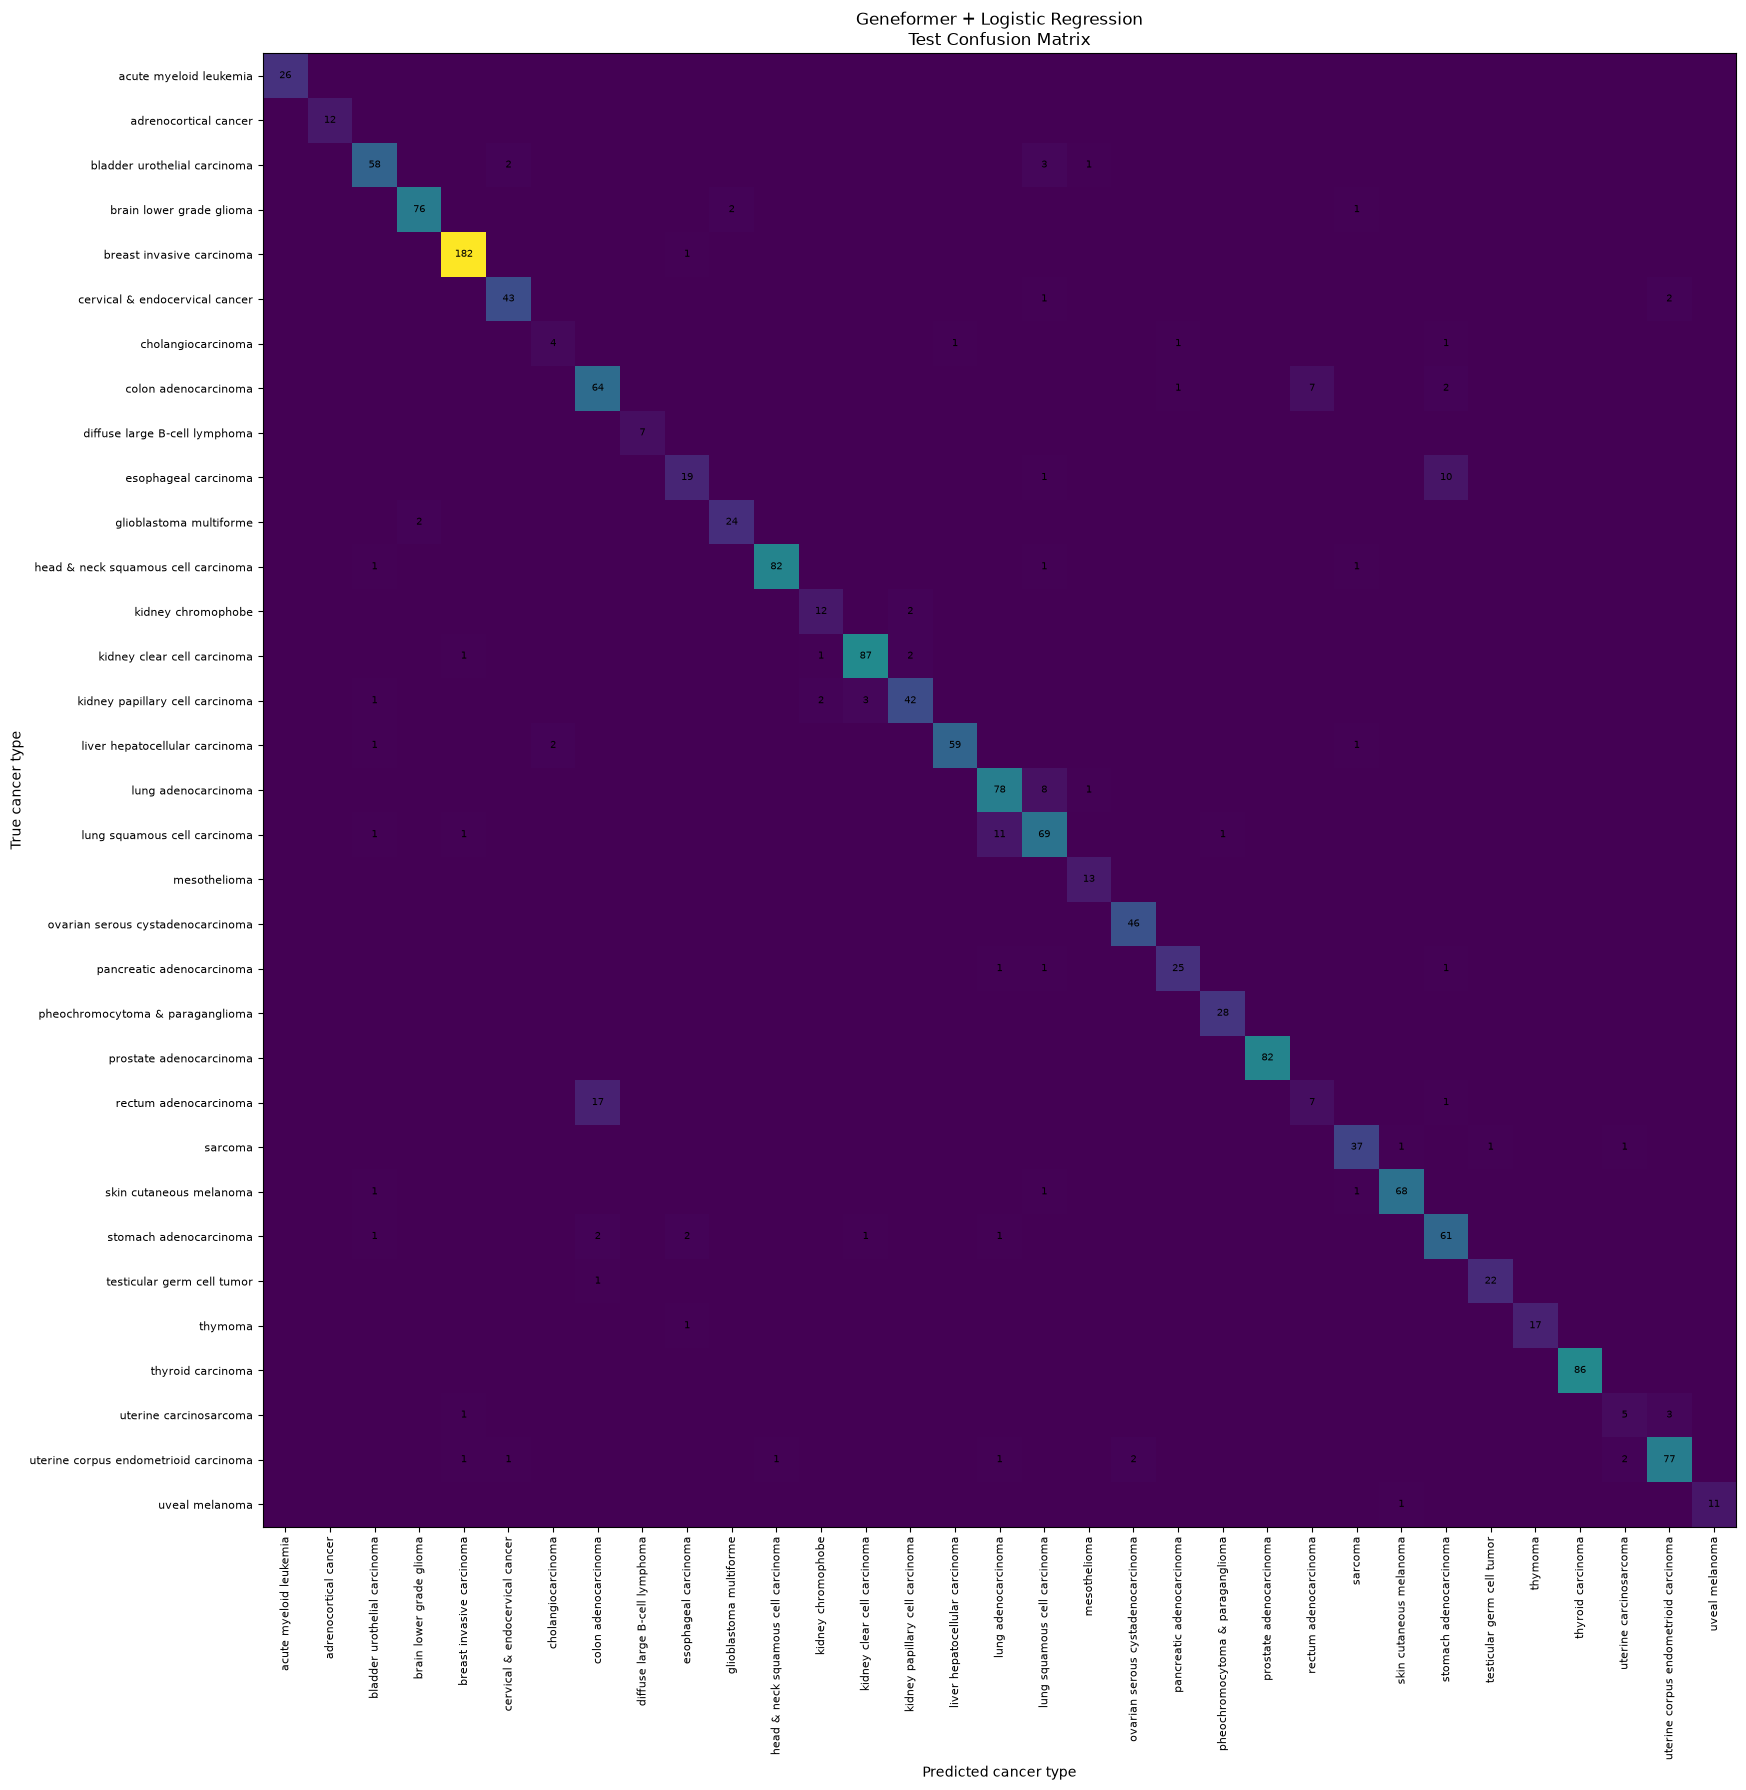


RESULTS SAVED
Per-cancer performance:
F:\GeneformerProject\data\geneformer_embeddings\logistic_regression_per_cancer_performance.csv

Confusion matrix:
F:\GeneformerProject\data\geneformer_embeddings\logistic_regression_confusion_matrix.csv

FINAL SUMMARY
Test Accuracy:       0.9216
Test Macro-F1:       0.8923
Test Weighted-F1:    0.9198
Test Macro ROC-AUC:  0.9980
Test Weighted AUC:   0.9979


In [3]:
# ============================================================
# GENEFORMER EMBEDDINGS
# LOGISTIC REGRESSION EVALUATION
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

# ============================================================
# 1. PATHS
# ============================================================

EMBEDDING_DIR = r"F:\GeneformerProject\data\geneformer_embeddings"
RESULTS_DIR = r"F:\GeneformerProject\data\geneformer_embeddings"

# ============================================================
# 2. LOAD EMBEDDINGS AND LABELS
# ============================================================

X_train = np.load(
    rf"{EMBEDDING_DIR}\train_embeddings.npy"
)

X_val = np.load(
    rf"{EMBEDDING_DIR}\validation_embeddings.npy"
)

X_test = np.load(
    rf"{EMBEDDING_DIR}\test_embeddings.npy"
)

y_train = np.load(
    rf"{EMBEDDING_DIR}\train_labels.npy"
)

y_val = np.load(
    rf"{EMBEDDING_DIR}\validation_labels.npy"
)

y_test = np.load(
    rf"{EMBEDDING_DIR}\test_labels.npy"
)

print("=" * 70)
print("DATA SHAPES")
print("=" * 70)

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_val:  ", X_val.shape)
print("y_val:  ", y_val.shape)
print("X_test: ", X_test.shape)
print("y_test: ", y_test.shape)


# ============================================================
# 3. CANCER TYPE NAMES
# ============================================================

cancer_names = [
    "acute myeloid leukemia",
    "adrenocortical cancer",
    "bladder urothelial carcinoma",
    "brain lower grade glioma",
    "breast invasive carcinoma",
    "cervical & endocervical cancer",
    "cholangiocarcinoma",
    "colon adenocarcinoma",
    "diffuse large B-cell lymphoma",
    "esophageal carcinoma",
    "glioblastoma multiforme",
    "head & neck squamous cell carcinoma",
    "kidney chromophobe",
    "kidney clear cell carcinoma",
    "kidney papillary cell carcinoma",
    "liver hepatocellular carcinoma",
    "lung adenocarcinoma",
    "lung squamous cell carcinoma",
    "mesothelioma",
    "ovarian serous cystadenocarcinoma",
    "pancreatic adenocarcinoma",
    "pheochromocytoma & paraganglioma",
    "prostate adenocarcinoma",
    "rectum adenocarcinoma",
    "sarcoma",
    "skin cutaneous melanoma",
    "stomach adenocarcinoma",
    "testicular germ cell tumor",
    "thymoma",
    "thyroid carcinoma",
    "uterine carcinosarcoma",
    "uterine corpus endometrioid carcinoma",
    "uveal melanoma"
]

# Check that labels correspond to these 33 classes
n_classes = len(cancer_names)

print("\nNumber of cancer types:", n_classes)

print("\nCancer classes:")
for i, name in enumerate(cancer_names):
    print(f"{i:2d}: {name}")


# ============================================================
# 4. TRAIN LOGISTIC REGRESSION
# ============================================================

print("\n" + "=" * 70)
print("TRAINING LOGISTIC REGRESSION")
print("=" * 70)

logreg = LogisticRegression(
    C=1.0,
    max_iter=2000,
    solver="lbfgs",
    random_state=42
)

logreg.fit(X_train, y_train)

print("✓ Training completed.")
print("Number of classes learned:", len(logreg.classes_))


# ============================================================
# 5. PREDICTIONS
# ============================================================

y_val_pred = logreg.predict(X_val)
y_test_pred = logreg.predict(X_test)

# Probability predictions
y_val_proba = logreg.predict_proba(X_val)
y_test_proba = logreg.predict_proba(X_test)


# ============================================================
# 6. BASIC PERFORMANCE
# ============================================================

val_accuracy = accuracy_score(y_val, y_val_pred)
val_macro_f1 = f1_score(
    y_val,
    y_val_pred,
    average="macro"
)
val_weighted_f1 = f1_score(
    y_val,
    y_val_pred,
    average="weighted"
)

test_accuracy = accuracy_score(y_test, y_test_pred)
test_macro_f1 = f1_score(
    y_test,
    y_test_pred,
    average="macro"
)
test_weighted_f1 = f1_score(
    y_test,
    y_test_pred,
    average="weighted"
)

print("\n" + "=" * 70)
print("VALIDATION RESULTS")
print("=" * 70)

print(f"Accuracy:    {val_accuracy:.4f}")
print(f"Macro-F1:    {val_macro_f1:.4f}")
print(f"Weighted-F1: {val_weighted_f1:.4f}")


print("\n" + "=" * 70)
print("TEST RESULTS")
print("=" * 70)

print(f"Accuracy:    {test_accuracy:.4f}")
print(f"Macro-F1:    {test_macro_f1:.4f}")
print(f"Weighted-F1: {test_weighted_f1:.4f}")


# ============================================================
# 7. CLASSIFICATION REPORT WITH CANCER NAMES
# ============================================================

print("\n" + "=" * 70)
print("TEST CLASSIFICATION REPORT")
print("=" * 70)

report_dict = classification_report(
    y_test,
    y_test_pred,
    labels=np.arange(n_classes),
    target_names=cancer_names,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report_dict).T

# Display only individual cancer types
per_class_df = report_df.iloc[:n_classes].copy()

# Add class number
per_class_df.insert(
    0,
    "class_id",
    np.arange(n_classes)
)

print(
    per_class_df[
        [
            "class_id",
            "precision",
            "recall",
            "f1-score",
            "support"
        ]
    ].to_string()
)


# ============================================================
# 8. ROC-AUC FOR EACH CANCER TYPE
# ============================================================

print("\n" + "=" * 70)
print("ONE-vs-REST ROC-AUC BY CANCER TYPE")
print("=" * 70)

auc_results = []

for class_id, cancer_name in enumerate(cancer_names):

    # Binary true labels for this cancer
    y_true_binary = (y_test == class_id).astype(int)

    # Probability assigned to this cancer
    y_score = y_test_proba[:, class_id]

    # Calculate one-vs-rest AUC
    try:
        auc = roc_auc_score(
            y_true_binary,
            y_score
        )
    except ValueError:
        auc = np.nan

    auc_results.append({
        "class_id": class_id,
        "cancer_type": cancer_name,
        "roc_auc": auc,
        "support": int(np.sum(y_true_binary))
    })

auc_df = pd.DataFrame(auc_results)

print(
    auc_df.to_string(
        index=False,
        formatters={
            "roc_auc": lambda x: f"{x:.4f}"
        }
    )
)


# ============================================================
# 9. MULTICLASS ROC-AUC
# ============================================================

macro_auc = roc_auc_score(
    y_test,
    y_test_proba,
    multi_class="ovr",
    average="macro"
)

weighted_auc = roc_auc_score(
    y_test,
    y_test_proba,
    multi_class="ovr",
    average="weighted"
)

print("\n" + "=" * 70)
print("OVERALL ROC-AUC")
print("=" * 70)

print(f"Macro ROC-AUC:    {macro_auc:.4f}")
print(f"Weighted ROC-AUC: {weighted_auc:.4f}")


# ============================================================
# 10. COMBINE F1 + AUC INTO ONE TABLE
# ============================================================

performance_df = per_class_df[
    [
        "class_id",
        "precision",
        "recall",
        "f1-score",
        "support"
    ]
].copy()

performance_df = performance_df.rename(
    columns={
        "f1-score": "f1"
    }
)

performance_df["cancer_type"] = cancer_names

performance_df = performance_df.merge(
    auc_df[
        [
            "class_id",
            "roc_auc"
        ]
    ],
    on="class_id",
    how="left"
)

performance_df = performance_df[
    [
        "class_id",
        "cancer_type",
        "precision",
        "recall",
        "f1",
        "roc_auc",
        "support"
    ]
]

print("\n" + "=" * 70)
print("COMPLETE PER-CANCER PERFORMANCE")
print("=" * 70)

print(
    performance_df.to_string(
        index=False,
        formatters={
            "precision": lambda x: f"{x:.4f}",
            "recall": lambda x: f"{x:.4f}",
            "f1": lambda x: f"{x:.4f}",
            "roc_auc": lambda x: f"{x:.4f}"
        }
    )
)


# ============================================================
# 11. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_test,
    y_test_pred,
    labels=np.arange(n_classes)
)

print("\n" + "=" * 70)
print("CONFUSION MATRIX")
print("=" * 70)

cm_df = pd.DataFrame(
    cm,
    index=cancer_names,
    columns=cancer_names
)

print(cm_df)


# ============================================================
# 12. PLOT CONFUSION MATRIX
# ============================================================

fig, ax = plt.subplots(
    figsize=(20, 18)
)

im = ax.imshow(cm)

ax.set_xticks(np.arange(n_classes))
ax.set_yticks(np.arange(n_classes))

ax.set_xticklabels(
    cancer_names,
    rotation=90,
    fontsize=8
)

ax.set_yticklabels(
    cancer_names,
    fontsize=8
)

ax.set_xlabel("Predicted cancer type")
ax.set_ylabel("True cancer type")

ax.set_title(
    "Geneformer + Logistic Regression\n"
    "Test Confusion Matrix"
)

# Add numbers to cells
for i in range(n_classes):
    for j in range(n_classes):
        if cm[i, j] > 0:
            ax.text(
                j,
                i,
                str(cm[i, j]),
                ha="center",
                va="center",
                fontsize=7
            )

plt.tight_layout()
plt.show()


# ============================================================
# 13. SAVE RESULTS
# ============================================================

performance_path = (
    rf"{RESULTS_DIR}\logistic_regression_per_cancer_performance.csv"
)

confusion_path = (
    rf"{RESULTS_DIR}\logistic_regression_confusion_matrix.csv"
)

performance_df.to_csv(
    performance_path,
    index=False
)

cm_df.to_csv(
    confusion_path
)

print("\n" + "=" * 70)
print("RESULTS SAVED")
print("=" * 70)

print("Per-cancer performance:")
print(performance_path)

print("\nConfusion matrix:")
print(confusion_path)


# ============================================================
# 14. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("FINAL SUMMARY")
print("=" * 70)

print(f"Test Accuracy:       {test_accuracy:.4f}")
print(f"Test Macro-F1:       {test_macro_f1:.4f}")
print(f"Test Weighted-F1:    {test_weighted_f1:.4f}")
print(f"Test Macro ROC-AUC:  {macro_auc:.4f}")
print(f"Test Weighted AUC:   {weighted_auc:.4f}")